In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sympy

In [ ]:
n_ = [int(n) for n in 1.1**np.arange(160)]
RNG = np.random.default_rng(seed=42)

In [ ]:
a, b = -2, 2

Wir betrachten hier die Funktion $f(t)=e^{-\cos(\pi t)}$ aus den Slides und verwenden die `scipy.integrate.quad`-Annäherung als Referenzwert. 

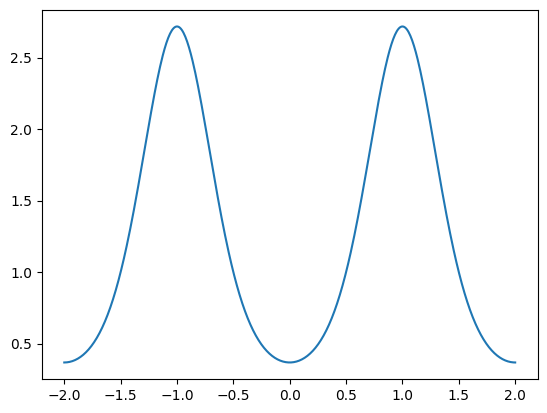

In [ ]:
f = lambda x: np.exp(-np.cos(np.pi * x))
I = scipy.integrate.quad(f, a, b)[0]

x_eval = np.linspace(a, b, 500)
plt.plot(x_eval, f(x_eval))

## Standard-Monte-Carlo
Zuerst berechnen wir die Standard-Mt.Carlo-methode für mehrere $n$

In [ ]:
errors_mtc = []
for n in n_:
    x = a + (b-a) * RNG.random(n)
    Q = (b-a)/n * np.sum(f(x))

    error = np.abs((Q - I) / I)
    errors_mtc.append(error)

## Control Variates
Jetzt verwenden wir die Methode der Control Variates. Hierzu definieren wir $\phi$ symbolisch und integrieren dies mithilfe von sympy: 

In [ ]:
t = sympy.symbols(("t"))

# Integriere Phi symbolisch
phi_expr = 1 - sympy.cos(sympy.pi * t) + (1/2)*(sympy.cos(sympy.pi * t)**2)
Phi_expr = sympy.integrate(phi_expr)
phi = sympy.lambdify(t, phi_expr, "numpy")
Phi = sympy.lambdify(t, Phi_expr, "numpy")
I_Phi = Phi(b) - Phi(a)

Nun führen wir die Monte-Carlo Quadratur über $f(t)-\phi(t)$ durch:

In [ ]:
errors_cv = []
for n in n_:
    x = a + (b-a) * RNG.random(n)
    Q = (b-a)/n * np.sum(f(x) - phi(x)) + I_Phi

    error = np.abs((Q - I) / I)
    errors_cv.append(error)

## Konvergenzplots

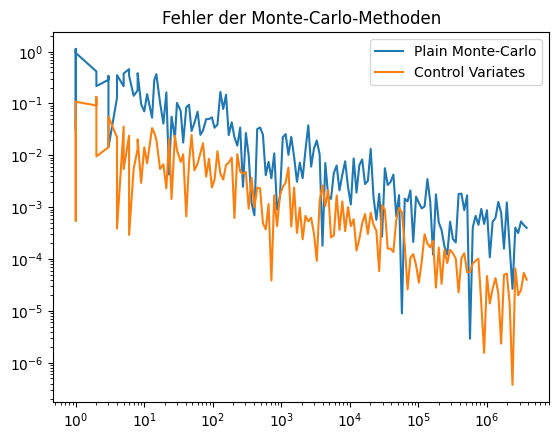

In [ ]:
plt.title("Fehler der Monte-Carlo-Methoden")
plt.loglog(n_, errors_mtc, label="Plain Monte-Carlo")
plt.loglog(n_, errors_cv, label="Control Variates")
plt.legend()
plt.xlabel=r"$n$"
plt.ylabel="relative error"